# Figure 3: liquid Intralipid phantom validation

Layout follows Figure 3 (`phantom_validation_src.pdf`) with panels (d)-(i) removed:

| Panel | Content | Source in `figures/data/figure3_liquid_phantom/` |
|:--|:--|:--|
| (a) | OCT instrument photo | `figure_rebuttal_liquid_phantom_a.jpeg` |
| (b) | OCT parameters box | drawn here as vector text from `figure_rebuttal_liquid_phantom_b_specs.json` (provenance: `_b_specs.md`) |
| (c) | Liquid Intralipid phantoms photo (rotated to landscape) | `figure_rebuttal_liquid_phantom_c.jpeg` |
| (d) | 3D measured dB volume, 3% H | `render_db_<RENDER_TAG>.pdf` (lossless 4000×4000 render), or re-rendered from `render_data_<RENDER_TAG>.npz` |
| (e) | 3D recovered μ volume, 3% H | `render_mu_<RENDER_TAG>.pdf` (lossless 4000×4000 render), or re-rendered from `render_data_<RENDER_TAG>.npz` |
| (f) | Concentration violins (Figure 3(l) style) | `violin_frame_means.npz`, `violin_regressions.csv` |
| (g) | Example A-lines: 1% H A-line 23 and 3% L A-line 179, both B-scan 256 | `aline_signals_selected.npz`, `aline_metrics_selected.csv` |

**Resolution.** In the PDFs every image is embedded at its native pixel count (no resampling); text, lines,
panel (b) and panels (f)-(g) are vector. The 3D renders are 4000×4000 px (above 1000 dpi at their printed size).
The photos in (a) and (c) are 768×1024 px originals, about 445 dpi at their printed size.

Individual panels are only previewed inline; the notebook saves just the full figure, as
`figures/output/figure3.{pdf,jpeg}` (PDF + 600 dpi JPEG).

**Panel (f).** Four violins per concentration: DiffOCT H (blue), CF H (green), DiffOCT L (orange),
CF L (green). Each violin holds the 512 B-scan means of one acquisition after the display filter
(Tukey 1.5 × IQR per group; no outliers drawn); the black dot is the mean of the displayed values.
Lines are the unfiltered regressions on the five volume means: DiffOCT per acquisition, CF pooled over H and L.

**Panel (g).** Measured corrected signal (green dashed), CF line (black) and DiffOCT prediction coloured
by μ(DiffOCT) − μ(CF), inside the CF fitting window; below, DiffOCT μ versus depth against the CF μ,
with the in-window RMSE of each method.

**Data provenance.** The production run is `experiments/REBUTTAL_liquid_intralipid_cf_comparison/runs/production_HL_full_depth_cf_gain_20260928T175833Z`
(full-depth DiffOCT, fixed per-A-line CF gain, 15,000 iterations). `staged_sources.json` lists each staged
file's source and SHA-256. The 3D volumes come from `experiments/REBUTTAL_liquid_intralipid_cf_comparison/render_3d_liquid.py`,
whose settings are recorded in `render_params_<RENDER_TAG>.json`. The notebook reads the 3D panels from the staged
render PDFs, which hold each 4000×4000 render losslessly (Flate). To rebuild them from `render_data_<RENDER_TAG>.npz`,
set the environment variable `RERENDER_3D=1`; this needs PyVista and about 4 GB of memory, and overwrites the PDFs
in the data folder. PyVista crashes inside a Jupyter kernel on this cluster, so for re-rendering export the setup and
(d)-(e) cells to a script and run it with `python`.

In [1]:
%matplotlib inline
import csv, json, os, sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.legend_handler import HandlerBase
from matplotlib.lines import Line2D
from PIL import Image

REPO_ROOT = os.path.abspath('..')
DATA_DIR  = os.path.join(REPO_ROOT, 'figures', 'data', 'figure3_liquid_phantom')
OUT_DIR   = os.path.join(REPO_ROOT, 'figures', 'output')
os.makedirs(OUT_DIR, exist_ok=True)

RENDER_TAG  = 'H_3pct_cfdepth225'   # which staged 3D render set to use for (d) and (e)
RERENDER_3D = os.environ.get('RERENDER_3D', '0') == '1'   # rebuild the (d)/(e) render PDFs from render_data_<RENDER_TAG>.npz
RENDER_WINDOW = (4000, 4000)        # render resolution in pixels when re-rendering

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.linewidth': 0.8,
                     'pdf.fonttype': 42, 'svg.fonttype': 'none'})

CONCS = [0.5, 1.0, 1.5, 2.0, 3.0]
BLUE, ORANGE, GREEN = '#5b8db8', '#e8a25a', 'green'          # Figure 3(l) colours
VWIDTH, CF_STEP = 0.11, 0.115                                # violin width; CF violin right of its DiffOCT violin
POSITIONS = {'H': -0.1725, 'L': 0.0575}                      # DiffOCT H, CF H, DiffOCT L, CF L centred on c
ALINES = [(0, '1% H\nB-scan 256 · A-line 23'), (3, '3% L\nB-scan 256 · A-line 179')] # rows of aline_signals_selected.npz (MATLAB 1-based indices)
DIFF_CMAP = LinearSegmentedColormap.from_list('mu_difference', ['#2166ac', '#67a9cf', '#9e9e9e', '#ef8a62', '#b2182b'])
DIFF_NORM = Normalize(-1, 1)
MEASURED, MEASURED_LW = '#00843d', 0.8


def path(name):
    return os.path.join(DATA_DIR, name)


def title(ax, text):
    ax.set_title(text, fontsize=11, fontweight='bold', loc='left', pad=4)


def write(fig, stem, **kw):
    """PDF/SVG + 600 dpi JPEG. With interpolation 'none' the PDF backend embeds each image at its native
    pixel count; any other setting resamples it to the savefig dpi (100) first. The JPEG is raster
    anyway, so there the images are downsampled with antialiasing instead."""
    images = [im for ax in fig.axes for im in ax.get_images()]
    for im in images:
        im.set_interpolation('none')
    fig.savefig(stem + '.pdf', facecolor='white', **kw)
    fig.savefig(stem + '.svg', facecolor='white', **kw)
    for im in images:
        im.set_interpolation('antialiased')
    fig.savefig(stem + '.jpeg', dpi=600, facecolor='white', pil_kwargs={'quality': 95}, **kw)


def crop_white(img, thr=245, pad=8):
    ink = (img < thr).any(axis=2)
    r, c = np.flatnonzero(ink.any(axis=1)), np.flatnonzero(ink.any(axis=0))
    return img[max(r[0] - pad, 0):r[-1] + pad, max(c[0] - pad, 0):c[-1] + pad]


def frame(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_color('black'); spine.set_linewidth(1.3)


def show(ax, img, border=False):
    ax.imshow(img)
    if border:
        frame(ax)
    else:
        ax.set_axis_off()


def standalone_image(img, label, border, width=4.0):
    fig = plt.figure(figsize=(width, width * img.shape[0] / img.shape[1]))
    ax = fig.add_axes([0, 0, 1, 1])
    show(ax, img, border=border); title(ax, label)
    plt.show()


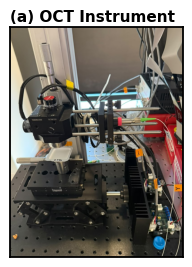

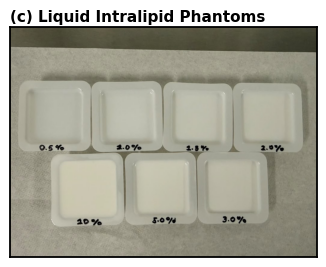

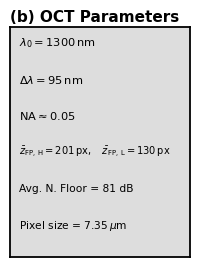

In [2]:
# ── Panels (a)-(c): photos and the parameter box ──────────────────────────
img_a = np.array(Image.open(path('figure_rebuttal_liquid_phantom_a.jpeg')).convert('RGB'))
img_c = np.rot90(np.array(Image.open(path('figure_rebuttal_liquid_phantom_c.jpeg')).convert('RGB')), k=1)

SPECS = json.load(open(path('figure_rebuttal_liquid_phantom_b_specs.json')))
B_ASPECT = 0.783                       # width / height of the parameter box (Figure 3(b) style)


def draw_params(ax, height_in):
    """Panel (b) as vector text: gray box, black border, rows scaled to the box height."""
    ax.set_facecolor('#dddddd'); frame(ax)
    fs = height_in * 72 * 15 / 302     # 15 pt rows in a 302 pt box
    zfp = SPECS['zFP_by_acquisition']
    rows = [
        (rf"$\lambda_0 = {SPECS['central_wavelength_nm']}\,\mathrm{{nm}}$", fs),
        (rf"$\Delta\lambda = {SPECS['full_bandwidth_nm']}\,\mathrm{{nm}}$", fs),
        (rf"$\mathrm{{NA}} \approx {SPECS['experimental_NA_approx']}$", fs),
        (rf"$\bar{{z}}_{{\mathrm{{FP,\,H}}}} = {zfp['H']['mean_px']:.0f}\,\mathrm{{px}},\quad "
         rf"\bar{{z}}_{{\mathrm{{FP,\,L}}}} = {zfp['L']['mean_px']:.0f}\,\mathrm{{px}}$", fs * 13 / 15),
        (f"Avg. N. Floor = {SPECS['noise_floor_mean_power_db']:.0f} dB", fs * 14 / 15),
        (rf"Pixel size = {SPECS['axial_pixel_size_water_um']:.2f}$\,\mu$m", fs * 14 / 15),
    ]
    for k, (text, size) in enumerate(rows):
        ax.text(0.05, 1 - (0.068 + 0.159 * k), text, fontsize=size, ha='left', va='center', transform=ax.transAxes)


LABELS_ABC = ('(a) OCT Instrument', '(b) OCT Parameters', '(c) Liquid Intralipid Phantoms')
for img, lab in ((img_a, LABELS_ABC[0]), (img_c, LABELS_ABC[2])):
    standalone_image(img, lab, border=True,
                     width=2.3 * img.shape[1] / img.shape[0])

fig = plt.figure(figsize=(2.3 * B_ASPECT, 2.3))
ax = fig.add_axes([0, 0, 1, 1]); draw_params(ax, 2.3); title(ax, LABELS_ABC[1])
plt.show()


Mask rule: Per A-line: original CF-window start <= depth < start + 225; intersect finite measured_db and mu_final; identical mask for both volumes. No comparison_mask or intensity-threshold filtering. Other voxels are set to the lower display limit (opacity 0); full depth coordinates kept.
  db: 3339x2994 px after cropping
  mu: 3304x2977 px after cropping


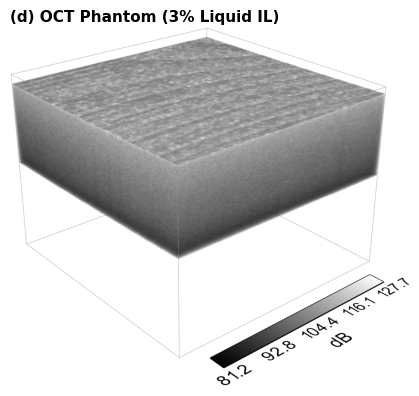

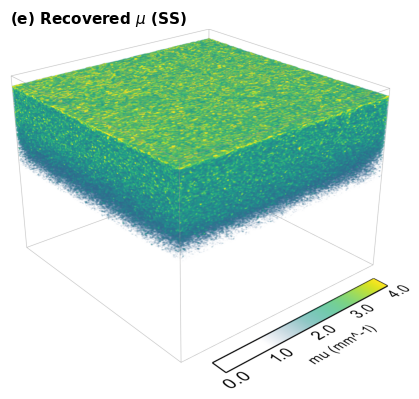

In [3]:
# ── Panels (d)-(e): 3D volume renders (3% H) ────────────────────────────────
params = json.load(open(path(f'render_params_{RENDER_TAG}.json')))
print('Mask rule:', params['mask_rule'])


def add_colorbar_3d(pl, bounds, cmap, clim, bar_title, opacity=None, n_labels=5, fmt='{:.1f}', line_width=4):
    """Outlined colour strip in the box's bottom plane along its front edge; labels in the same plane."""
    import pyvista as pv
    x0, x1, y0, y1, z0, z1 = bounds
    L = x1 - x0
    w, gap = 0.07 * L, 0.07 * L
    ya, yb = y0 - gap - w, y0 - gap
    xs, xe = x1 - 0.08 * L, x0 + 0.08 * L
    t = np.linspace(0, 1, 256)
    strip = pv.StructuredGrid()
    strip.points = np.array([[xs + f * (xe - xs), y, z1] for f in t for y in (ya, yb)])
    strip.dimensions = (2, len(t), 1)
    strip.point_data['s'] = np.repeat(clim[0] + t * (clim[1] - clim[0]), 2)
    kw = dict(opacity=opacity) if opacity is not None else {}
    pl.add_mesh(strip, scalars='s', cmap=cmap, clim=clim, show_scalar_bar=False, lighting=False, **kw)
    corners = np.array([[xs, ya, z1], [xe, ya, z1], [xe, yb, z1], [xs, yb, z1], [xs, ya, z1]])
    pl.add_mesh(pv.lines_from_points(corners), color='black', line_width=line_width)
    R = np.array([[-1, 0, 0], [0, 1, 0], [0, 0, -1]], float)   # text lies in the plane, readable from the camera

    def text(s, height, cx, cy):
        m = pv.Text3D(s, depth=0.0)
        b = m.bounds
        m.points = (m.points - [(b[0] + b[1]) / 2, (b[2] + b[3]) / 2, 0]) * (height / max(b[3] - b[2], 1e-9))
        m.points = m.points @ R.T + [cx, cy, z1]
        pl.add_mesh(m, color='black', lighting=False)

    th = 0.05 * L
    for i in range(n_labels):
        f = i / (n_labels - 1)
        text(fmt.format(clim[0] + f * (clim[1] - clim[0])), th, xs + f * (xe - xs), ya - 1.0 * th)
    text(bar_title, 1.1 * th, (xs + xe) / 2, ya - 2.9 * th)


def rerender(name):
    """Render one volume from the staged raw data (settings from render_params, resolution
    RENDER_WINDOW) and store it losslessly as render_<name>_<RENDER_TAG>.pdf in DATA_DIR."""
    import pyvista as pv
    sys.path.insert(0, REPO_ROOT)
    from src.visualization import volume_to_imagedata, setup_camera
    pv.OFF_SCREEN = True
    with np.load(path(f'render_data_{RENDER_TAG}.npz')) as d:
        vol = d['db_vol' if name == 'db' else 'mu_vol']
    ps = params['pixel_size_mm']
    grid = volume_to_imagedata(vol, ps['dx'], ps['dy'], ps['dz'], 'v')
    cmap, clim, opacity = params[f'cmap_{name}'], params[f'{name}_clim'], params[f'opacity_{name}']
    scale = RENDER_WINDOW[0] / params['window_size'][0]      # keep line widths proportional
    pl = pv.Plotter(off_screen=True, window_size=list(RENDER_WINDOW), border=False)
    pl.set_background('white')
    pl.add_volume(grid, scalars='v', cmap=cmap, clim=clim, opacity=opacity, show_scalar_bar=False)
    pl.add_mesh(grid.outline(), color='gray', line_width=1 * scale)
    add_colorbar_3d(pl, grid.bounds, cmap, clim, 'dB' if name == 'db' else 'mu (mm^-1)',
                    opacity=opacity if name == 'mu' else None, line_width=4 * scale)
    setup_camera(pl, grid, azimuth=params['camera']['azimuth'], elevation=params['camera']['elevation'])
    img = pl.screenshot(None, transparent_background=False, return_img=True)
    pl.close()
    write_render_pdf(img, path(f'render_{name}_{RENDER_TAG}.pdf'))


def write_render_pdf(img, pdf_path, dpi=600):
    """One page holding the RGB array as a Flate (lossless) image; page size is nominal (dpi)."""
    import io, fitz
    buf = io.BytesIO(); Image.fromarray(img).save(buf, 'PNG')
    doc = fitz.open()
    page = doc.new_page(width=img.shape[1] * 72 / dpi, height=img.shape[0] * 72 / dpi)
    page.insert_image(page.rect, stream=buf.getvalue())
    doc.save(pdf_path, deflate=True); doc.close()


def read_render_pdf(pdf_path):
    """The embedded render's pixels, exactly as stored."""
    import fitz
    with fitz.open(pdf_path) as doc:
        pix = fitz.Pixmap(doc, doc[0].get_images()[0][0])
        return np.frombuffer(pix.samples, np.uint8).reshape(pix.height, pix.width, pix.n)[..., :3].copy()


renders = {}
for name in ('db', 'mu'):
    if RERENDER_3D:
        rerender(name)
    renders[name] = crop_white(read_render_pdf(path(f'render_{name}_{RENDER_TAG}.pdf')))
    print(f'  {name}: {renders[name].shape[1]}x{renders[name].shape[0]} px after cropping')

img_d, img_e = renders['db'], renders['mu']
LABEL_D, LABEL_E = '(d) OCT Phantom (3% Liquid IL)', r'(e) Recovered $\mu$ (SS)'
standalone_image(img_d, LABEL_D, border=False)
standalone_image(img_e, LABEL_E, border=False)


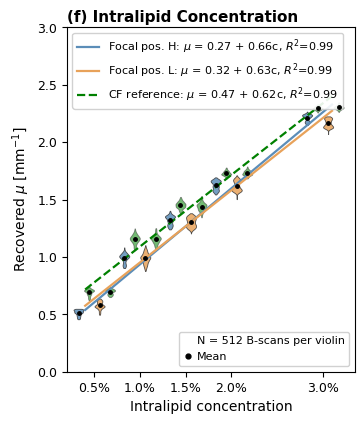

In [4]:
# ── Panel (f): concentration violins, Figure 3(l) style ─────────────────────
def panel_f(ax):
    with np.load(path('violin_frame_means.npz')) as d:
        vol, method, vals, keep = d['python_volume'], d['method'], d['frame_values'], d['retained']
    reg = {(r['acquisition'], r['method']): r for r in csv.DictReader(open(path('violin_regressions.csv')))}
    xs = np.linspace(0.4, 3.1, 50)

    def violin(data, x, colour, alpha):
        parts = ax.violinplot([data], positions=[x], widths=VWIDTH, showextrema=False, bw_method='scott')
        for body in parts['bodies']:
            body.set_facecolor(colour); body.set_edgecolor('#333333')
            body.set_linewidth(0.6); body.set_alpha(alpha)
        ax.plot(x, data.mean(), 'o', ms=2.5, color='black', zorder=6)       # mean of displayed values

    handles = []
    for acq, k, colour in (('H', 0, BLUE), ('L', 1, ORANGE)):
        for j, c in enumerate(CONCS):
            v = 2 * j + k                                   # volumes: 0.5,1,1.5,2,3% x (H even, L odd)
            base = c + POSITIONS[acq]
            row = np.flatnonzero((vol == v) & (method == 'diffoct'))[0]
            violin(vals[row][keep[row]], base, colour, 0.85)
            row = np.flatnonzero((vol == v) & (method == 'cf'))[0]
            violin(vals[row][keep[row]], base + CF_STEP, GREEN, 0.55)
        r = reg[(acq, 'diffoct')]
        a, b, r2 = float(r['intercept_mm_inv']), float(r['slope_mm_inv_per_percentage_point']), float(r['r_squared'])
        ax.plot(xs, a + b * xs, color=colour, lw=1.6, zorder=3)
        handles.append(Line2D([], [], color=colour, lw=1.6,
                              label=f'Focal pos. {acq}: $\\mu$ = {a:.2f} + {b:.2f}c, $R^2$={r2:.2f}'))
    r = reg[('H+L', 'cf')]
    a, b, r2 = float(r['intercept_mm_inv']), float(r['slope_mm_inv_per_percentage_point']), float(r['r_squared'])
    ax.plot(xs, a + b * xs, '--', color=GREEN, lw=1.6, zorder=3)
    handles.append(Line2D([], [], color=GREEN, lw=1.6, ls='--',
                          label=f'CF reference: $\\mu$ = {a:.2f} + {b:.2f}c, $R^2$={r2:.2f}'))
    ax.add_artist(ax.legend(handles=handles, loc='upper left', fontsize=8, framealpha=0.9))
    key = [Line2D([], [], ls='', label='N = 512 B-scans per violin'),
           Line2D([], [], marker='o', ls='', ms=3.5, color='black', label='Mean')]
    ax.legend(handles=key, loc='lower right', fontsize=8, framealpha=0.9, handlelength=0.8, handletextpad=0.4)
    ax.set_xticks(CONCS, [f'{c:.1f}%' for c in CONCS])
    ax.set_xlim(0.2, 3.35); ax.set_ylim(0, 3.0)
    ax.set_xlabel('Intralipid concentration', fontsize=10)
    ax.set_ylabel(r'Recovered $\mu$ [mm$^{-1}$]', fontsize=10)
    ax.tick_params(labelsize=9)


LABEL_F = '(f) Intralipid Concentration'
fig = plt.figure(figsize=(3.6, 4.2))
ax = fig.add_axes([0.16, 0.1, 0.8, 0.82])
panel_f(ax); title(ax, LABEL_F)
plt.show()


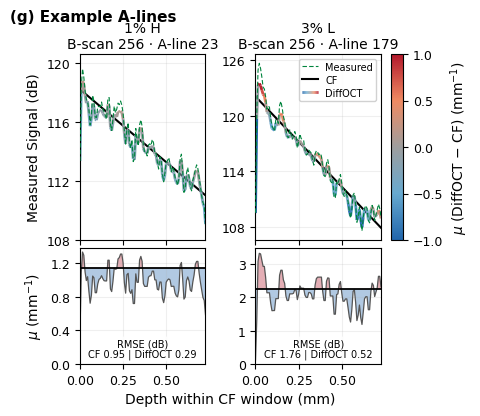

In [5]:
# ── Panel (g): example A-lines with the mu(DiffOCT) - mu(CF) colour scale ──
class GradientLine:
    """Legend proxy for the DiffOCT line coloured by mu(DiffOCT) - mu(CF)."""


class HandlerGradientLine(HandlerBase):
    def create_artists(self, legend, orig, xd, yd, width, height, fontsize, trans):
        x = np.linspace(-xd, -xd + width, 32)
        y = np.full_like(x, -yd + height / 2)
        seg = np.stack([np.column_stack([x[:-1], y[:-1]]), np.column_stack([x[1:], y[1:]])], axis=1)
        lc = LineCollection(seg, cmap=DIFF_CMAP, norm=DIFF_NORM, linewidths=2.0, transform=trans)
        lc.set_array(np.linspace(-1, 1, len(seg)))
        return [lc]


def panel_g(axes_top, axes_bot, cax):
    with np.load(path('aline_signals_selected.npz')) as d:
        D = {k: d[k] for k in d.files}
    saved = list(csv.DictReader(open(path('aline_metrics_selected.csv'))))
    for j, (i, label) in enumerate(ALINES):
        top, bot = axes_top[j], axes_bot[j]
        z = np.flatnonzero(D['original_fit_mask'][i].astype(bool))       # CF fitting window
        depth = D['depth_below_window_start_mm'][i][z]
        valid = D['valid_signal_mask'][i][z].astype(bool) & np.isfinite(D['measured_corrected_db'][i][z])
        meas = np.where(valid, D['measured_corrected_db'][i][z], np.nan)
        pred = np.where(valid, D['diffoct_prediction_corrected_db'][i][z], np.nan)
        cfl = np.where(valid, D['cf_analytic_line_corrected_db'][i][z], np.nan)
        mu = np.where(valid, D['diffoct_mu_mm_inv'][i][z], np.nan)
        cf = float(D['cf_mu_mm_inv'][i])
        cm = D['comparison_mask'][i].astype(bool)
        cf_rmse = float(np.sqrt(np.mean((D['measured_corrected_db'][i][cm] - D['cf_analytic_line_corrected_db'][i][cm]) ** 2)))
        df_rmse = float(np.sqrt(np.mean((D['measured_corrected_db'][i][cm] - D['diffoct_prediction_corrected_db'][i][cm]) ** 2)))
        assert abs(cf_rmse - float(saved[i]['cf_rmse_db'])) < 1e-6
        assert abs(df_rmse - float(saved[i]['diffoct_rmse_db'])) < 1e-6

        top.plot(depth, meas, color=MEASURED, lw=MEASURED_LW, ls=(0, (4, 2)), zorder=4)
        top.plot(depth, cfl, color='black', lw=1.5)
        p = np.column_stack([depth, pred])
        seg = np.stack([p[:-1], p[1:]], axis=1)
        v = (mu[:-1] + mu[1:]) / 2 - cf
        good = np.isfinite(seg).all(axis=(1, 2)) & np.isfinite(v)
        lc = LineCollection(seg[good], cmap=DIFF_CMAP, norm=DIFF_NORM, linewidths=2.0)
        lc.set_array(v[good]); top.add_collection(lc)
        top.set_title(label, fontsize=10, pad=4)
        finite = np.concatenate([x[np.isfinite(x)] for x in (meas, pred, cfl)])
        top.set_ylim(finite.min() - 1, finite.max() + 1)

        bot.fill_between(depth, cf, mu, where=mu >= cf, color='#b2182b', alpha=0.35, lw=0, interpolate=True)
        bot.fill_between(depth, cf, mu, where=mu < cf, color='#2166ac', alpha=0.35, lw=0, interpolate=True)
        bot.plot(depth, mu, color='#555555', lw=0.9)
        bot.axhline(cf, color='black', lw=1.3)
        bot.set_ylim(0, None)
        bot.text(0.5, 0.04, f'RMSE (dB)\nCF {cf_rmse:.2f} | DiffOCT {df_rmse:.2f}', transform=bot.transAxes,
                 ha='center', va='bottom', fontsize=7, linespacing=1.1,
                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.85))
        for ax in (top, bot):
            ax.set_xlim(0, depth[-1]); ax.set_xticks([0, 0.25, 0.5])
            ax.yaxis.set_major_locator(plt.MaxNLocator(4))
            ax.grid(alpha=0.2); ax.tick_params(labelsize=9)
        top.tick_params(labelbottom=False)
    axes_top[0].set_ylabel('Measured Signal (dB)', fontsize=10)
    axes_bot[0].set_ylabel(r'$\mu$ (mm$^{-1}$)', fontsize=10)
    axes_top[1].legend(handles=[Line2D([], [], color=MEASURED, lw=MEASURED_LW, ls=(0, (4, 2))),
                                Line2D([], [], color='black', lw=1.5), GradientLine()],
                       labels=['Measured', 'CF', 'DiffOCT'], handler_map={GradientLine: HandlerGradientLine()},
                       loc='upper right', fontsize=7, handlelength=1.6, labelspacing=0.3, borderpad=0.3,
                       framealpha=0.9)
    cb = plt.colorbar(plt.cm.ScalarMappable(norm=DIFF_NORM, cmap=DIFF_CMAP), cax=cax)
    cb.set_label(r'$\mu$ (DiffOCT $-$ CF) (mm$^{-1}$)', fontsize=10)
    cb.ax.tick_params(labelsize=9)


def layout_g(fig, W, H, xg, yt, bottom):
    """Two A-line columns (signal over mu) plus the colour bar; all sizes in inches from the top-left."""
    def ax_at(x, y, w, h):
        return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])
    wcb, gapcb, gapcol = 0.12, 0.1, 0.5
    wcol = (W - 0.62 - xg - wcb - gapcb - gapcol) / 2
    ht = (bottom - yt) * 0.6
    hb = (bottom - yt) - ht - 0.08
    tops = [ax_at(xg + k * (wcol + gapcol), yt, wcol, ht) for k in range(2)]
    bots = [ax_at(xg + k * (wcol + gapcol), yt + ht + 0.08, wcol, hb) for k in range(2)]
    for k in range(2):
        bots[k].sharex(tops[k])
    cax = ax_at(xg + 2 * wcol + gapcol + gapcb, yt, wcb, ht)
    panel_g(tops, bots, cax)
    fig.text((xg + wcol + gapcol / 2) / W, 1 - (bottom + 0.35) / H, 'Depth within CF window (mm)',
             fontsize=10, ha='center', va='center')


LABEL_G = '(g) Example A-lines'
W, H = 4.6, 4.2
fig = plt.figure(figsize=(W, H))
layout_g(fig, W, H, xg=0.75, yt=0.55, bottom=H - 0.55)
fig.text(0.05 / W, 1 - 0.25 / H, LABEL_G, fontsize=11, fontweight='bold', ha='left', va='bottom')
plt.show()


  saved figure3.{pdf,jpeg,svg}


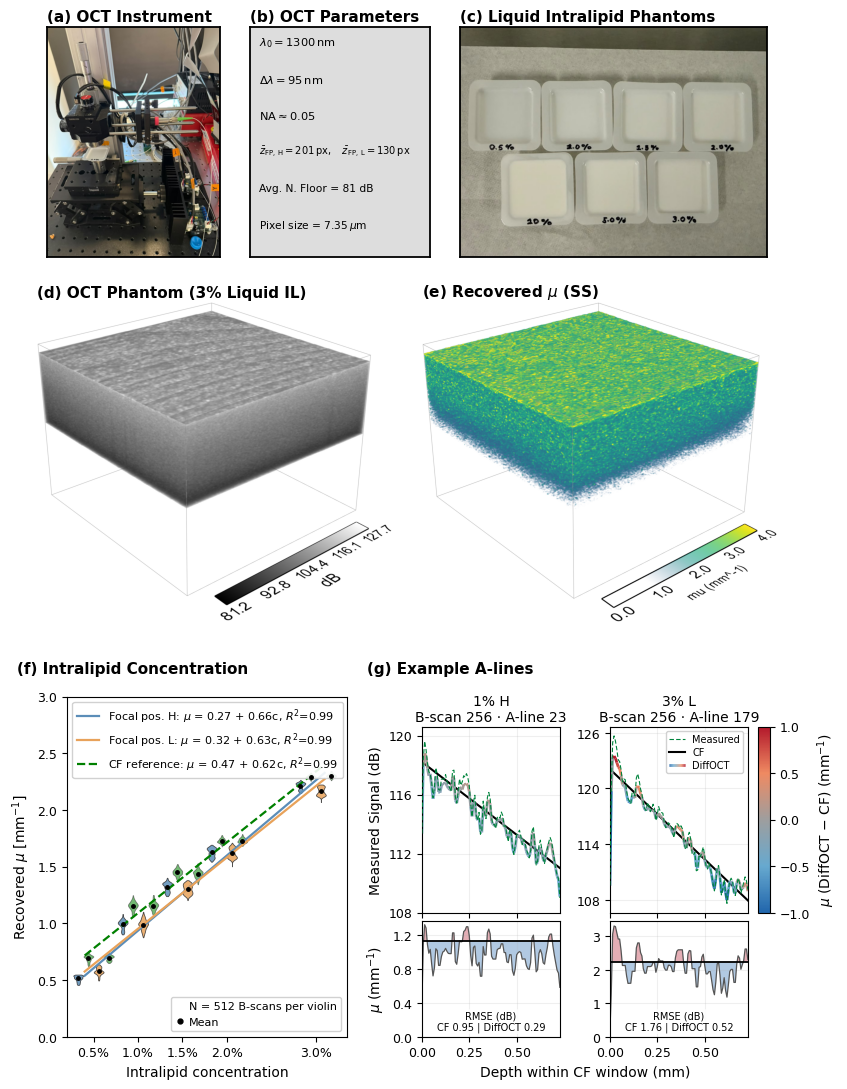

In [6]:
# ── Full figure ─────────────────────────────────────────────────────────────
W, H = 8.5, 11.0
fig = plt.figure(figsize=(W, H))
m, gapx = 0.35, 0.3


def ax_at(x, y, w, h):                          # inches from the top-left corner
    return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])


# Row 1: (a) | (b) | (c), common height, black borders
h1, y1 = 2.3, 0.35
ws = [h1 * img_a.shape[1] / img_a.shape[0], h1 * B_ASPECT, h1 * img_c.shape[1] / img_c.shape[0]]
x = (W - sum(ws) - 2 * gapx) / 2
for im, w, lab in zip((img_a, None, img_c), ws, LABELS_ABC):
    ax = ax_at(x, y1, w, h1)
    if im is None:
        draw_params(ax, h1)
    else:
        show(ax, im, border=True)
    title(ax, lab); x += w + gapx

# Row 2: (d) | (e)
y2 = y1 + h1 + 0.45
w2 = 3.55
h2 = max(w2 * im.shape[0] / im.shape[1] for im in (img_d, img_e))
for k, (im, lab) in enumerate(((img_d, LABEL_D), (img_e, LABEL_E))):
    ax = ax_at((W - 2 * w2 - gapx) / 2 + k * (w2 + gapx), y2, w2, h2); show(ax, im); title(ax, lab)

# Row 3: (f) | (g)
y3 = y2 + h2 + 0.55
ybody = y3 + 0.2
xf, wf = m + 0.5, 2.8
panel_f(ax_at(xf, ybody, wf, H - ybody - 0.55))
xg = xf + wf + 0.75
layout_g(fig, W, H, xg=xg, yt=ybody + 0.3, bottom=H - 0.55)
for x_, lab in ((xf - 0.5, LABEL_F), (xg - 0.55, LABEL_G)):
    fig.text(x_ / W, 1 - y3 / H, lab, fontsize=11, fontweight='bold', ha='left', va='bottom')

stem = os.path.join(OUT_DIR, 'figure3')
write(fig, stem)
print('  saved figure3.{pdf,jpeg,svg}')
plt.show()
